# Ajustes con omega libre

Etapa exploratoria, 2026-10-27. Materia conservada + sector oscuro del paper.
No son intervalos de confianza ni evidencia de cruce. Los parámetros permanecen constantes en cada trayectoria.

| Modelo | chi² | D0 | Advertencia |
|---|---:|---:|---|
| LCDM | 1399.795388 | 1 | Control |
| wCDM | 1395.018196 | 1 | Control |
| diffusion_Dpositive | 1394.974756 | 16 | Límites alpha_bar y beta |
| diffusion_Dnegative | 1394.846065 | -8.32379e-07 | Próximo a D0=0 |

La difusión mejora chi² en menos de 0.18 respecto a wCDM en esta exploración. No se interpreta como detección: faltan incertidumbres, sensibilidad a límites y validación de mínimos globales.
La solución D<0 tiene D0 muy próximo a cero, próxima a una degeneración física.


In [ ]:
from pathlib import Path
import sys, json
import pandas as pd
from IPython.display import display, Image
root=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'src/observations').is_dir() or (p/'cosmo_singularities/src/observations').is_dir())
if not (root/'src/observations').is_dir(): root=root/'cosmo_singularities'
sys.path.insert(0,str(root))
run=root/'data/observations/results/free_omega_20261027T232141679155Z'
report=json.loads((run/'fits.json').read_text())
display(pd.DataFrame([{"model":n,"chi2":v['chi2'],"D0":v['D0'],"grid_delta":v['grid_delta_chi2'],"at_bound":v['at_bound']} for n,v in report['results'].items()]))


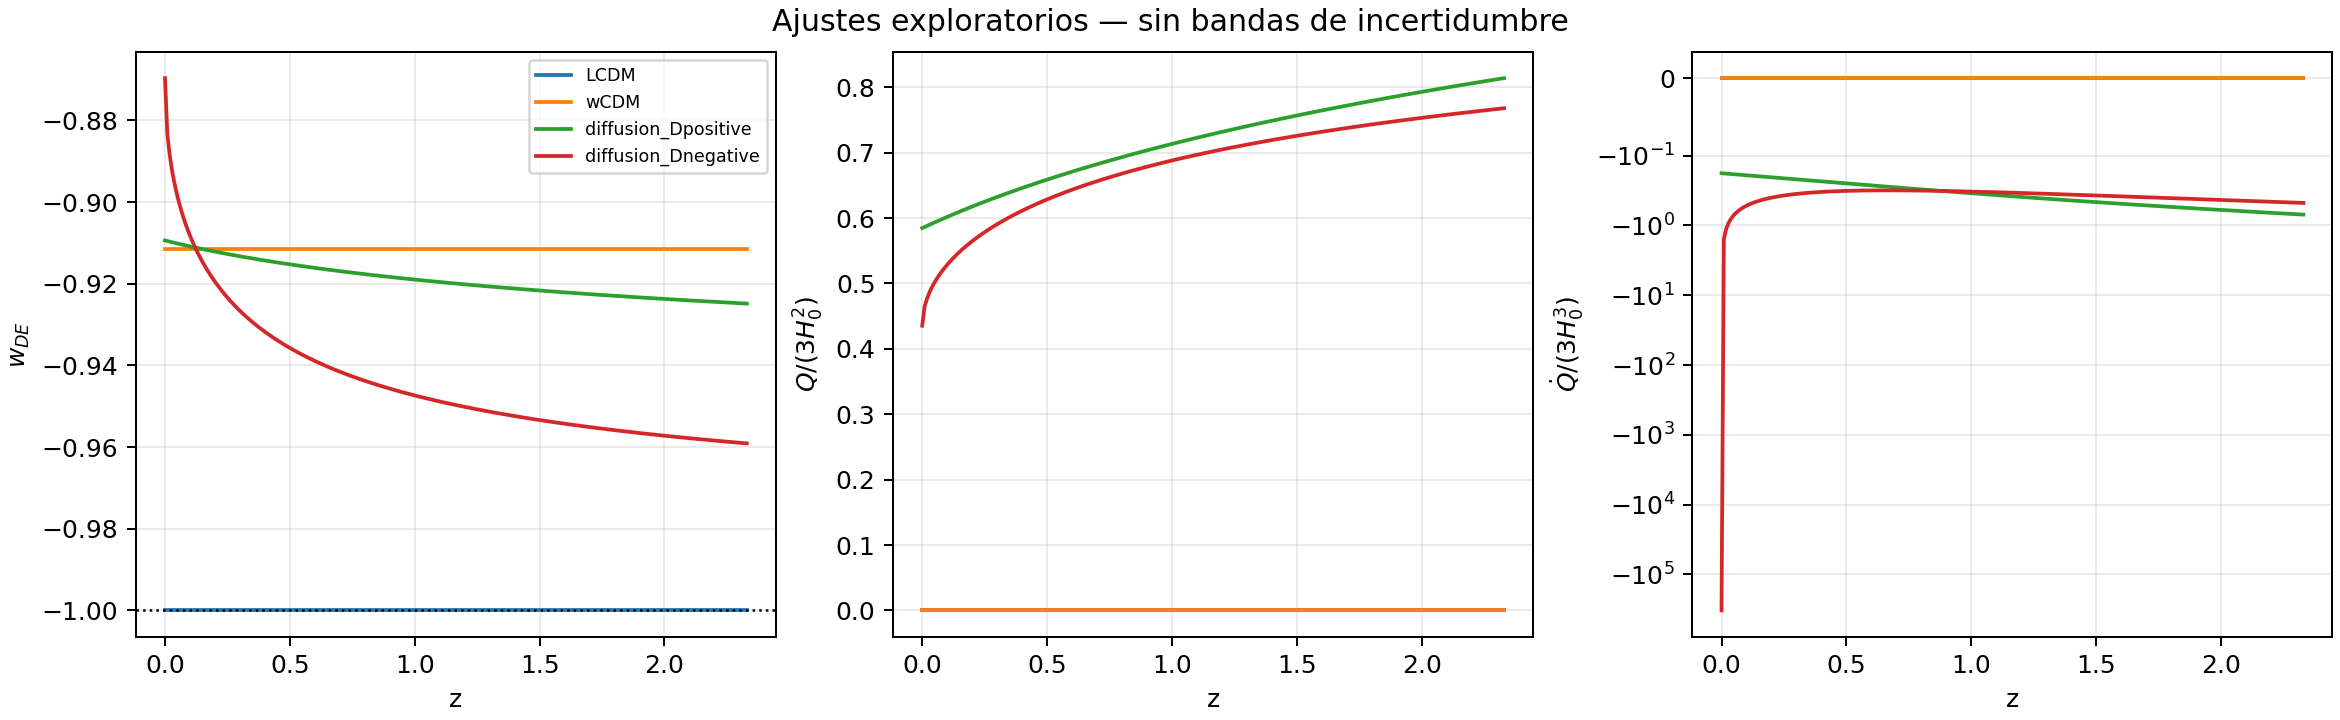

In [ ]:
display(Image(filename=str(run/'reconstructions.png')))


## Parámetros y trazabilidad

Cada archivo contiene inicios, límites, métodos, hashes de código, versiones y procedencia de datos. Las curvas corresponden a puntos de ajuste; no representan bandas posteriores. La ejecución previa se conserva con ADVERTENCIA.md por un fallo detectado en el buscador local.

In [ ]:
for name,result in report['results'].items():
    print(name,dict(zip(result['names'],result['parameters'])))
    print('Degeneraciones exactas:',result['degeneracies'])


## Reproducir

Desde cosmo_singularities, ejecutar `python3 -m scripts.fit_barotropic_observations --dataset joint`. Cambiar joint por bao o sn para ajustes separados.

Véase docs/INFERENCIA_BAROTROPICA.md para derivación, selección de datos, límites y pendientes científicos.

Documentación de Pantheon+: https://github.com/PantheonPlusSH0ES/DataRelease/tree/main/Pantheon%2B_Data/4_DISTANCES_AND_COVAR